# B-cell Epitope Dataset Exploration

Explore the general B-cell, SARS, and COVID CSVs in `dataset/`. This notebook checks structure and quality, describes peptide lengths and numeric epitope properties, and compares datasets visually.

**Interpretation:** sources may have been assembled or labeled differently. Treat `target` as source-specific; do not assume labels are equivalent across datasets. Descriptive associations are not causal evidence. The notebook does not modify the source files or train a model.

Run cells from top to bottom with the project root as the working directory.

**Note:** This notebook is generated by Copilot.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

DATASET_DIR = Path.cwd() / "dataset"
DATASET_FILES = {
    "B-cell": "input_bcell.csv",
    "SARS": "input_sars.csv",
    "COVID": "input_covid.csv",
}

datasets = {}
for source, filename in DATASET_FILES.items():
    csv_path = DATASET_DIR / filename
    if not csv_path.is_file():
        raise FileNotFoundError(
            f"Could not find {csv_path}. Run from the project root."
        )
    datasets[source] = pd.read_csv(csv_path)

print(f"Loaded {len(datasets)} datasets from {DATASET_DIR.resolve()}")

Loaded 3 datasets from D:\Data\Daffa M Azhar\Kerja\Publikasi\B Cell Epitope\dataset


## Dataset overview

Review row counts and schemas first. A missing `target` column is not treated as a negative label.

In [2]:
overview = pd.DataFrame(
    {
        source: {
            "rows": len(data),
            "columns": len(data.columns),
            "has_target": "target" in data.columns,
            "unique_parent_proteins": (
                data["parent_protein_id"].nunique()
                if "parent_protein_id" in data.columns
                else pd.NA
            ),
        }
        for source, data in datasets.items()
    }
).T
display(overview)

display(pd.DataFrame([
    {"source": source, "columns": ", ".join(data.columns)}
    for source, data in datasets.items()
]))

for source, data in datasets.items():
    print(f"\n{source} — first five rows")
    display(data.head())

,rows,columns,has_target,unique_parent_proteins
B-cell,14387,14,True,760
SARS,520,14,True,1
COVID,20312,13,False,1


,source,columns
0,B-cell,"parent_protein_id, protein_seq, start_position, end_posi..."
1,SARS,"parent_protein_id, protein_seq, start_position, end_posi..."
2,COVID,"parent_protein_id, protein_seq, start_position, end_posi..."



B-cell — first five rows


,parent_protein_id,protein_seq,start_position,end_position,peptide_seq,chou_fasman,emini,kolaskar_tongaonkar,parker,isoelectric_point,aromaticity,hydrophobicity,stability,target
0,A2T3T0,MDVLYSLSKTLKDARDKIVEGTLYSNVSDLIQQFNQMIITMNGNEFQTGGIGNLPI...,161,165,SASFT,1.016,0.703,1.018,2.22,5.810364,0.103275,-0.143829,40.273300,1
1,F0V2I4,MTIHKVAINGFGRIGRLLFRNLLSSQGVQVVAVNDVVDIKVLTHLLVYDSAQGKLK...,251,255,LCLKI,0.770,0.179,1.199,-3.86,6.210876,0.065476,-0.036905,24.998512,1
2,O75508,MVATCLQVVGFVTSFVGWIGVIVTTSTNDWVVTCGYTIPTCRKLDELGSKGLWADC...,145,149,AHRET,0.852,3.427,0.960,4.28,8.223938,0.091787,0.879227,27.863333,1
3,O84462,MTNSISGYQPTVTTSTSSTTSASGASGSLGASSVSTTANATVTQTANATNSAATSS...,152,156,SNYDD,1.410,2.548,0.936,6.32,4.237976,0.044776,-0.521393,30.765373,1
4,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKPLSVSYDQATS...,85,89,DGTYR,1.214,1.908,0.937,4.64,6.867493,0.103846,-0.578846,21.684615,1



SARS — first five rows


,parent_protein_id,protein_seq,start_position,end_position,peptide_seq,chou_fasman,emini,kolaskar_tongaonkar,parker,isoelectric_point,aromaticity,hydrophobicity,stability,target
0,AAU93319,MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYLTQ...,1,17,MFIFLLFLTLTSGSDLD,0.887,0.040,1.056,-2.159,5.569763,0.116335,-0.061116,33.205116,0
1,AAU93319,MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYLTQ...,1,15,MFIFLLFLTLTSGSD,0.869,0.047,1.056,-2.500,5.569763,0.116335,-0.061116,33.205116,0
2,AAU93319,MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYLTQ...,2,10,FIFLLFLTL,0.621,0.042,1.148,-7.467,5.569763,0.116335,-0.061116,33.205116,0
3,AAU93319,MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYLTQ...,6,20,LFLTLTSGSDLDRCT,1.021,0.230,1.049,0.927,5.569763,0.116335,-0.061116,33.205116,0
4,AAU93319,MFIFLLFLTLTSGSDLDRCTTFDDVQAPNYTQHTSSMRGVYYPDEIFRSDTLYLTQ...,9,25,TLTSGSDLDRCTTFDDV,1.089,0.627,1.015,3.165,5.569763,0.116335,-0.061116,33.205116,0



COVID — first five rows


,parent_protein_id,protein_seq,start_position,end_position,peptide_seq,chou_fasman,emini,kolaskar_tongaonkar,parker,isoelectric_point,aromaticity,hydrophobicity,stability
0,6VYB_A,MGILPSPGMPALLSLVSLLSVLLMGCVAETGTQCVNLTTRTQLPPAYTNSFTRGVY...,1,5,MGILP,0.948,0.280,1.033,-2.72,6.03595,0.10929,-0.138642,31.377603
1,6VYB_A,MGILPSPGMPALLSLVSLLSVLLMGCVAETGTQCVNLTTRTQLPPAYTNSFTRGVY...,2,6,GILPS,1.114,0.379,1.070,-0.58,6.03595,0.10929,-0.138642,31.377603
2,6VYB_A,MGILPSPGMPALLSLVSLLSVLLMGCVAETGTQCVNLTTRTQLPPAYTNSFTRGVY...,3,7,ILPSP,1.106,0.592,1.108,-1.30,6.03595,0.10929,-0.138642,31.377603
3,6VYB_A,MGILPSPGMPALLSLVSLLSVLLMGCVAETGTQCVNLTTRTQLPPAYTNSFTRGVY...,4,8,LPSPG,1.324,0.836,1.053,1.44,6.03595,0.10929,-0.138642,31.377603
4,6VYB_A,MGILPSPGMPALLSLVSLLSVLLMGCVAETGTQCVNLTTRTQLPPAYTNSFTRGVY...,5,9,PSPGM,1.326,1.004,0.968,2.44,6.03595,0.10929,-0.138642,31.377603


## Data quality

Missing values and exact duplicate rows are reported without removing or repairing any records.

In [3]:
quality_rows = []
missing_rows = []
for source, data in datasets.items():
    quality_rows.append({
        "source": source,
        "rows": len(data),
        "exact_duplicate_rows": int(data.duplicated().sum()),
        "rows_with_any_missing": int(data.isna().any(axis=1).sum()),
    })
    missing_rows.extend(
        {"source": source, "column": column, "missing": int(count)}
        for column, count in data.isna().sum().items()
        if count > 0
    )

display(pd.DataFrame(quality_rows).set_index("source"))
missing_summary = pd.DataFrame(missing_rows, columns=["source", "column", "missing"])
display(missing_summary if not missing_summary.empty else "No missing values found.")

,rows,exact_duplicate_rows,rows_with_any_missing
source,,,
B-cell,14387,5,0
SARS,520,6,0
COVID,20312,0,0


'No missing values found.'

## Source-specific target distributions

Counts and percentages are calculated within each source. Check label definitions before comparing labels across sources.

In [4]:
label_rows = []
for source, data in datasets.items():
    if "target" not in data.columns:
        print(f"{source}: no target column")
        continue
    counts = data["target"].value_counts(dropna=False)
    percentages = data["target"].value_counts(dropna=False, normalize=True).mul(100)
    for label, count in counts.items():
        label_rows.append({
            "source": source,
            "target": label,
            "count": int(count),
            "percent_within_source": float(percentages.loc[label]),
        })

label_summary = pd.DataFrame(
    label_rows,
    columns=["source", "target", "count", "percent_within_source"],
)
display(label_summary)

COVID: no target column


,source,target,count,percent_within_source
0,B-cell,0,10485,72.878293
1,B-cell,1,3902,27.121707
2,SARS,0,380,73.076923
3,SARS,1,140,26.923077


## Peptide lengths

Lengths are calculated from `peptide_seq`. Missing sequences remain missing; each source is plotted separately.

,n,mean,median,min,max
source,,,,,
B-cell,14387,11.409258,10.0,5,15
SARS,520,19.005769,15.0,5,393
COVID,20312,12.483261,12.0,5,20


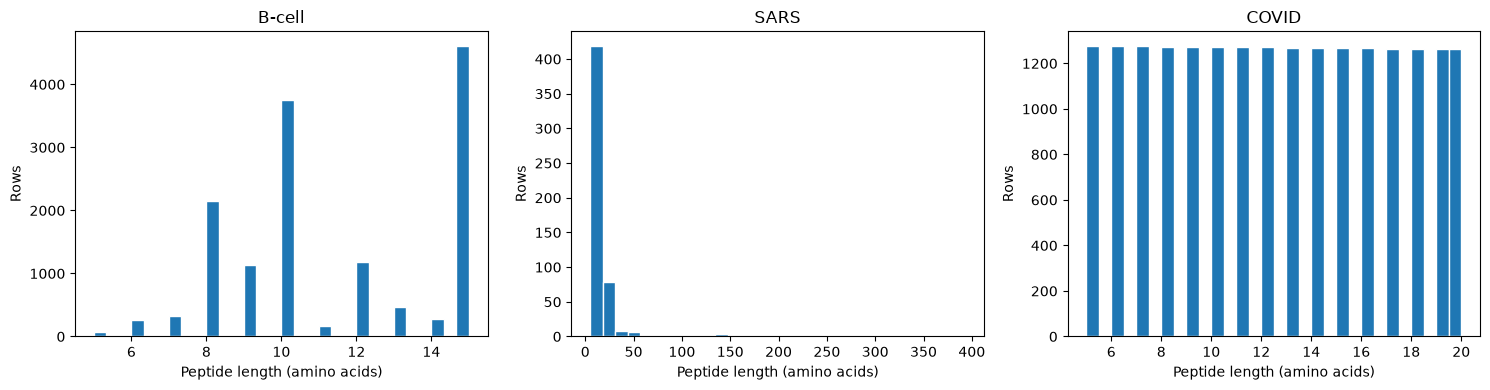

In [5]:
datasets_with_lengths = {}
length_rows = []
for source, data in datasets.items():
    if "peptide_seq" not in data.columns:
        print(f"{source}: no peptide_seq column; skipping")
        continue
    data_with_length = data.assign(
        peptide_length=data["peptide_seq"].astype("string").str.len()
    )
    datasets_with_lengths[source] = data_with_length
    lengths = data_with_length["peptide_length"].dropna()
    if not lengths.empty:
        length_rows.append({
            "source": source,
            "n": int(lengths.count()),
            "mean": lengths.mean(),
            "median": lengths.median(),
            "min": lengths.min(),
            "max": lengths.max(),
        })

length_summary = pd.DataFrame(
    length_rows, columns=["source", "n", "mean", "median", "min", "max"]
)
display(length_summary.set_index("source") if not length_summary.empty else "No lengths available.")

plot_count = max(len(datasets_with_lengths), 1)
fig, axes = plt.subplots(1, plot_count, figsize=(5 * plot_count, 4), squeeze=False)
for ax, (source, data) in zip(axes[0], datasets_with_lengths.items()):
    lengths = data["peptide_length"].dropna()
    if not lengths.empty:
        ax.hist(lengths, bins=30, edgecolor="white")
    ax.set(title=source, xlabel="Peptide length (amino acids)", ylabel="Rows")
fig.tight_layout()

## Coordinate consistency

For 1-based inclusive coordinates, peptide length should equal `end_position - start_position + 1`. This diagnostic does not correct records; missing values and invalid coordinates are counted separately.

In [6]:
coordinate_rows = []
for source, data in datasets.items():
    required = {"start_position", "end_position", "peptide_seq"}
    if not required.issubset(data.columns):
        print(f"{source}: missing coordinate or peptide columns; skipping")
        continue

    start = pd.to_numeric(data["start_position"], errors="coerce")
    end = pd.to_numeric(data["end_position"], errors="coerce")
    peptide_length = data["peptide_seq"].astype("string").str.len()
    has_coordinates = start.notna() & end.notna()
    invalid = has_coordinates & ((start < 1) | (end < start))
    comparable = has_coordinates & peptide_length.notna() & ~invalid
    mismatch = comparable & (peptide_length != (end - start + 1))
    coordinate_rows.append({
        "source": source,
        "rows": len(data),
        "missing_coordinate_or_peptide": int((~(has_coordinates & peptide_length.notna())).sum()),
        "invalid_start_or_end": int(invalid.sum()),
        "length_mismatch_1_based_inclusive": int(mismatch.sum()),
    })

coordinate_summary = pd.DataFrame(coordinate_rows)
display(coordinate_summary.set_index("source") if not coordinate_summary.empty else "No required coordinate columns found.")

,rows,missing_coordinate_or_peptide,invalid_start_or_end,length_mismatch_1_based_inclusive
source,,,,
B-cell,14387,0,0,0
SARS,520,0,0,0
COVID,20312,0,0,0


## Numeric epitope properties

Summaries exclude positional coordinates and `target`. Where `target` exists, boxplots show properties by labels within that source only. These descriptive comparisons do not establish predictive value.


B-cell: 8 numeric property columns


,count,mean,std,min,25%,50%,75%,max
chou_fasman,14387.0,0.994706,0.124772,0.534000,0.911000,0.990000,1.074000,1.546000
emini,14387.0,1.059788,1.621931,0.000000,0.248000,0.556000,1.209000,27.189000
kolaskar_tongaonkar,14387.0,1.021188,0.053804,0.838000,0.986000,1.020000,1.055000,1.255000
parker,14387.0,1.767137,1.968985,-9.029000,0.600000,1.793000,3.009500,9.120000
isoelectric_point,14387.0,7.067472,1.888708,3.686096,5.621033,6.499573,8.676575,12.232727
aromaticity,14387.0,0.075727,0.025767,0.000000,0.060606,0.074534,0.091312,0.182254
hydrophobicity,14387.0,-0.406097,0.394618,-1.971171,-0.606215,-0.330540,-0.189591,1.267089
stability,14387.0,43.703902,16.682362,5.448936,31.614529,42.287268,49.101172,137.046667


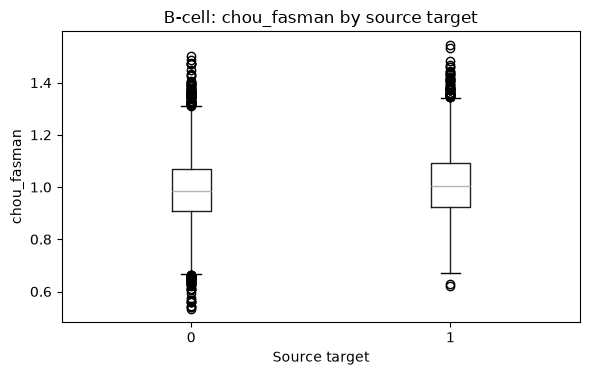

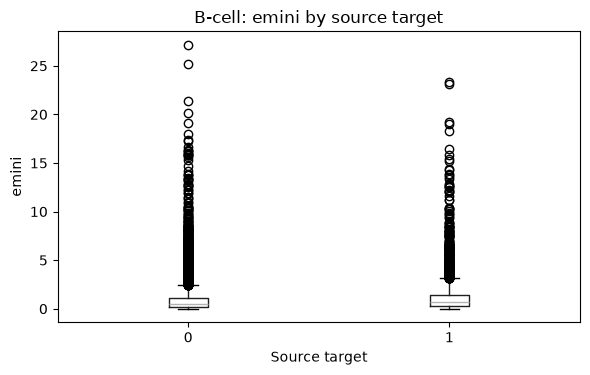

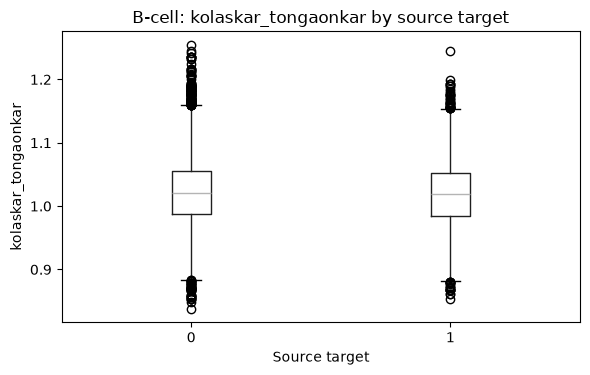

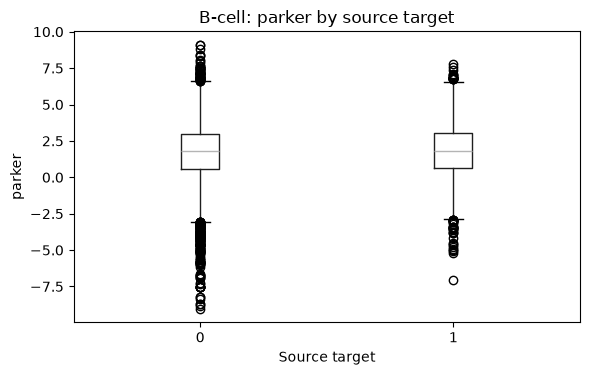


SARS: 8 numeric property columns


,count,mean,std,min,25%,50%,75%,max
chou_fasman,520.0,1.000442,8.719025e-02,0.621000,0.949000,1.009000,1.055250,1.317000
emini,520.0,1.719804,4.736354e+00,0.000000,0.179750,0.439500,1.181250,40.605000
kolaskar_tongaonkar,520.0,1.038960,3.797840e-02,0.908000,1.013000,1.036000,1.058000,1.228000
parker,520.0,1.278696,1.418791e+00,-7.467000,0.534500,1.412000,2.245000,4.907000
isoelectric_point,520.0,5.569763,0.000000e+00,5.569763,5.569763,5.569763,5.569763,5.569763
aromaticity,520.0,0.116335,2.778230e-17,0.116335,0.116335,0.116335,0.116335,0.116335
hydrophobicity,520.0,-0.061116,6.945576e-18,-0.061116,-0.061116,-0.061116,-0.061116,-0.061116
stability,520.0,33.205116,1.422454e-14,33.205116,33.205116,33.205116,33.205116,33.205116


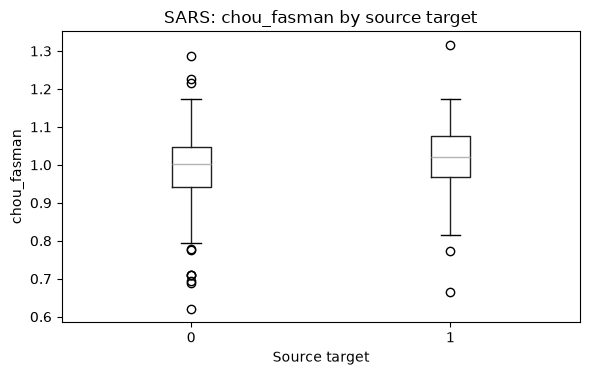

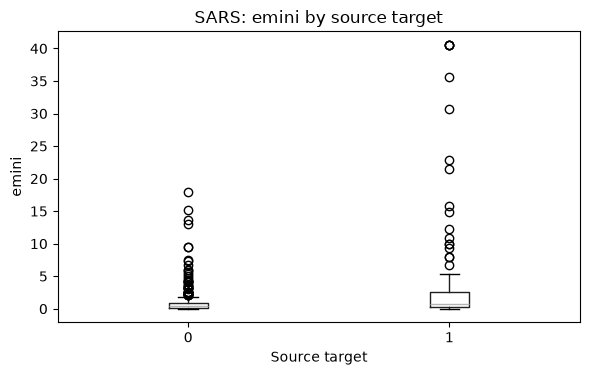

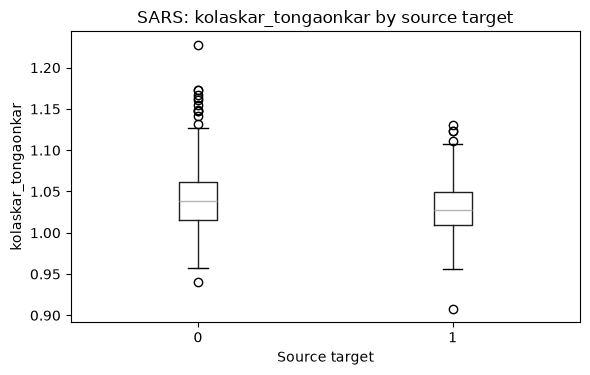

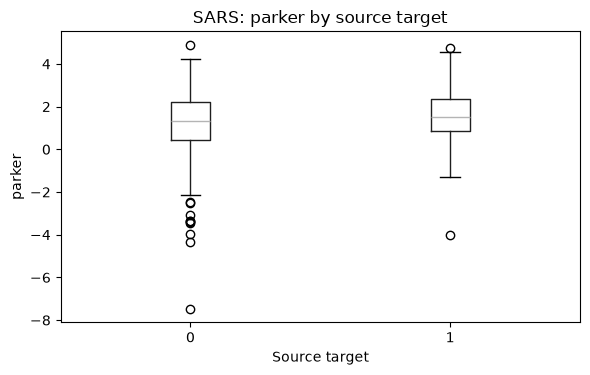


COVID: 8 numeric property columns


,count,mean,std,min,25%,50%,75%,max
chou_fasman,20312.0,1.003054,1.061910e-01,0.596000,0.935000,1.001000,1.067000,1.538000
emini,20312.0,0.999996,1.287882e+00,0.003000,0.272000,0.587000,1.222000,18.298000
kolaskar_tongaonkar,20312.0,1.037257,4.667680e-02,0.837000,1.008000,1.035000,1.064000,1.282000
parker,20312.0,1.334786,1.539362e+00,-7.317000,0.453000,1.406000,2.289000,7.300000
isoelectric_point,20312.0,6.035950,0.000000e+00,6.035950,6.035950,6.035950,6.035950,6.035950
aromaticity,20312.0,0.109290,2.775626e-17,0.109290,0.109290,0.109290,0.109290,0.109290
hydrophobicity,20312.0,-0.138642,2.775626e-17,-0.138642,-0.138642,-0.138642,-0.138642,-0.138642
stability,20312.0,31.377603,0.000000e+00,31.377603,31.377603,31.377603,31.377603,31.377603


In [7]:
excluded = {"start_position", "end_position", "target"}
for source, data in datasets.items():
    numeric_columns = [
        column for column in data.select_dtypes(include="number").columns
        if column not in excluded
    ]
    print(f"\n{source}: {len(numeric_columns)} numeric property columns")
    if not numeric_columns:
        continue
    display(data[numeric_columns].describe().T)

    if "target" not in data.columns:
        continue
    for feature in numeric_columns[:4]:
        grouped = data[["target", feature]].dropna(subset=[feature])
        if grouped.empty or grouped["target"].nunique(dropna=False) < 2:
            continue
        ax = grouped.boxplot(column=feature, by="target", figsize=(6, 4), grid=False)
        ax.set(title=f"{source}: {feature} by source target", xlabel="Source target", ylabel=feature)
        plt.suptitle("")
        plt.tight_layout()
        plt.show()

,rows,unique_parent_proteins
B-cell,14387,760
SARS,520,1
COVID,20312,1


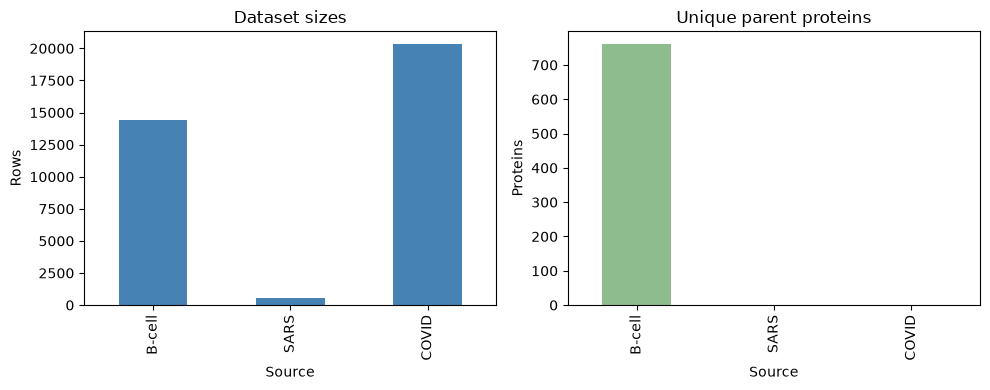

In [8]:
row_counts = pd.Series({source: len(data) for source, data in datasets.items()}, name="rows")
protein_counts = pd.Series({
    source: data["parent_protein_id"].nunique()
    for source, data in datasets.items()
    if "parent_protein_id" in data.columns
}, name="unique_parent_proteins")
display(pd.concat([row_counts, protein_counts], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
row_counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Dataset sizes", xlabel="Source", ylabel="Rows")
protein_counts.plot(kind="bar", ax=axes[1], color="darkseagreen")
axes[1].set(title="Unique parent proteins", xlabel="Source", ylabel="Proteins")
fig.tight_layout()

## Questions for follow-up

- What do the target labels mean in each source, and are labeling protocols comparable?
- Are duplicate or overlapping peptides concentrated within particular parent proteins?
- Do coordinate mismatches reflect different conventions, preprocessing, or data errors?
- How do numeric properties behave after accounting for repeated peptides from the same protein?
- Which comparisons are supported by the sampling design, and what biological validation is available?

Before statistical testing or modeling, define the question, document label provenance, and account for dependence between peptides from the same parent protein.